# Per-multiplier deep-dive

Single approximate multiplier across the (dataset, model) grid for one framework: accuracy table, drop bar chart, and confusion matrix. Reads `runs.csv` written by the sweep notebook.

**How to use:** set the parameters and Run All.
- `FRAMEWORK` -- `"adapt"` or `"transaxx"`.
- `MULTIPLIER` -- which approximate multiplier to inspect.
- `DATASET` -- `"all"`, `"cifar10"`, or `"cifar100"`.
- `CM_PICK` -- the `(dataset, model)` cell whose confusion matrix is plotted.

In [1]:
# Edit these and re-run all cells below.
FRAMEWORK  = "adapt"             # 'adapt' or 'transaxx'
MULTIPLIER = "mul8s_fpga_ish_3"  # which approximate multiplier to inspect
DATASET    = "all"               # 'all', 'cifar10', or 'cifar100'
BASELINE   = "mul8s_acc"         # reference for accuracy-drop calculations
CM_PICK    = ("cifar10", "resnet20")  # (dataset, model) cell for the confusion matrix

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

def find_results(framework):
    """Locate the dir holding runs.csv. Works inside the docker image
    (cwd = examples/, results at ./results) and on the host
    (cwd = docker/notebooks/, results at ../results/<framework>)."""
    for c in [Path("results"), Path(f"../results/{framework}"),
              Path(f"results/{framework}"), Path(f"../../docker/results/{framework}")]:
        if (c / "runs.csv").exists():
            return c
    raise FileNotFoundError(
        f"no runs.csv for '{framework}' (looked in ./results and "
        f"../results/{framework}) -- run the sweep notebook first")

RESULTS_DIR = find_results(FRAMEWORK)
CSV_PATH    = RESULTS_DIR / "runs.csv"
CM_DIR      = RESULTS_DIR / "confusion_matrices"   # dataset-foldered layout
RUNS_DIR    = RESULTS_DIR / "runs"                 # legacy hash-named layout (fallback)
EXPORTS     = RESULTS_DIR / "exports"
df = pd.read_csv(CSV_PATH)

if DATASET != "all":
    df = df[df.dataset == DATASET].copy()

print(f"reading {CSV_PATH.resolve()}")
df.head()

reading /work/results/adapt/runs.csv


,run_id,timestamp,dataset,model,multiplier,retrained_epochs,top1,top5,n_samples,runtime_s,notes
0,9e9e9f991b9e,2026-06-04T10:03:07,cifar10,resnet20,mul8s_fpga_ish_1,0,91.3862,99.8297,9984,26.2,NaN
1,c71cbb6b1c19,2026-06-04T10:04:33,cifar10,resnet20,mul8s_fpga_ish_1,3,88.6619,99.3389,9984,24.9,NaN
2,d152c9658992,2026-06-04T10:05:08,cifar10,resnet20,mul8s_fpga_ish_2,0,92.0373,99.8097,9984,25.0,NaN
3,9ba487777e82,2026-06-04T10:06:32,cifar10,resnet20,mul8s_fpga_ish_2,3,89.1426,99.3289,9984,25.3,NaN
4,a1f26922693e,2026-06-04T10:07:08,cifar10,resnet20,mul8s_fpga_ish_3,0,92.1575,99.8097,9984,25.6,NaN


## Top-1 / top-5 table for this multiplier

One row per (dataset, model). Columns: top1 / top5 for the selected multiplier and the baseline, eval-only and after retraining, plus the drop vs baseline.

In [3]:
def view(mult, retrained):
    sub = df[(df.multiplier == mult) & (df.retrained_epochs == retrained)]
    return sub.set_index(["dataset", "model"])[["top1", "top5"]]

mult_eval  = view(MULTIPLIER, 0).rename(columns={"top1": "mult_top1_eval",     "top5": "mult_top5_eval"})
base_eval  = view(BASELINE,   0).rename(columns={"top1": "base_top1_eval",     "top5": "base_top5_eval"})
retrained_epochs_present = sorted({r for r in df.retrained_epochs.unique() if r > 0})
tbl = mult_eval.join(base_eval, how="outer")

for r in retrained_epochs_present:
    mult_r = view(MULTIPLIER, r).rename(columns={"top1": f"mult_top1_rt{r}", "top5": f"mult_top5_rt{r}"})
    base_r = view(BASELINE,   r).rename(columns={"top1": f"base_top1_rt{r}", "top5": f"base_top5_rt{r}"})
    tbl = tbl.join(mult_r, how="outer").join(base_r, how="outer")

tbl["drop_top1_eval"] = tbl["base_top1_eval"] - tbl["mult_top1_eval"]
for r in retrained_epochs_present:
    tbl[f"drop_top1_rt{r}"] = tbl[f"base_top1_rt{r}"] - tbl[f"mult_top1_rt{r}"]

for ds, sub in tbl.groupby(level="dataset"):
    d = EXPORTS / ds; d.mkdir(parents=True, exist_ok=True)
    sub.round(4).to_csv(d / f"deepdive_{MULTIPLIER}.csv")

tbl.round(3)

mult_top1_eval  mult_top5_eval  base_top1_eval  \
dataset  model                                                      
cifar10  resnet20          92.158          99.810          92.107   
         resnet56          94.131          99.810          94.111   
         vgg11_bn          91.917          99.649          92.117   
cifar100 resnet20          68.079          90.765          68.179   
         resnet56          72.346          91.897          72.316   
         vgg11_bn          70.653          88.692          70.683   

                   base_top5_eval  mult_top1_rt3  mult_top5_rt3  \
dataset  model                                                    
cifar10  resnet20          99.800         89.012         99.299   
         resnet56          99.830         91.797         99.559   
         vgg11_bn          99.649         91.326         99.529   
cifar100 resnet20          90.805         62.590         86.879   
         resnet56          91.887         67.248         87.931   
         vgg11_bn          88.962         68.029         86.709   

                   base_top1_rt3  base_top5_rt3  drop_top1_eval  drop_top1_rt3  
dataset  model                                                                  
cifar10  resnet20         89.143         99.319           -0.05          0.130  
         resnet56         91.817         99.559           -0.02          0.020  
         vgg11_bn         91.346         99.539            0.20          0.020  
cifar100 resnet20         62.740         86.799            0.10          0.150  
         resnet56         67.668         87.931           -0.03          0.421  
         vgg11_bn         68.049         86.619            0.03          0.020

## Accuracy drop bar chart

Grouped by model, faceted by dataset. Eval-only and each retrained variant side-by-side so the gap shows what retraining buys back.

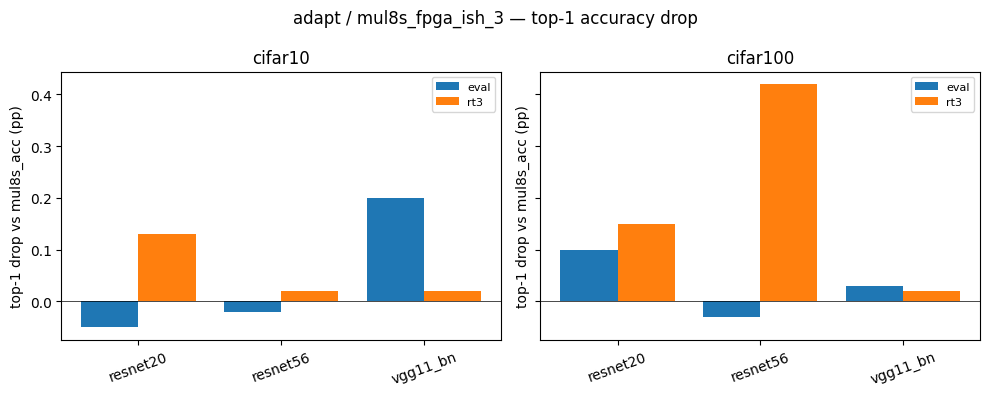

In [4]:
datasets = sorted(df.dataset.unique())
models   = sorted(df.model.unique())
variants = [("eval", 0)] + [(f"rt{r}", r) for r in retrained_epochs_present]

fig, axes = plt.subplots(1, len(datasets), figsize=(5 * len(datasets), 4), sharey=True)
if len(datasets) == 1:
    axes = [axes]

x = np.arange(len(models))
w = 0.8 / max(len(variants), 1)

for ax, ds in zip(axes, datasets):
    for i, (label, r) in enumerate(variants):
        col = f"drop_top1_{label}"
        if col not in tbl.columns:
            continue
        vals = [tbl.loc[(ds, m), col] if (ds, m) in tbl.index else np.nan for m in models]
        ax.bar(x + i * w - 0.4 + w / 2, vals, width=w, label=label)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=20)
    ax.set_title(ds)
    ax.set_ylabel(f"top-1 drop vs {BASELINE} (pp)")
    ax.axhline(0, color="k", lw=0.5)
    ax.legend(loc="upper right", fontsize=8)

fig.suptitle(f"{FRAMEWORK} / {MULTIPLIER} — top-1 accuracy drop")
fig.tight_layout()
EXPORTS.mkdir(parents=True, exist_ok=True)
fig.savefig(EXPORTS / f"deepdive_{MULTIPLIER}_drop.png", dpi=120, bbox_inches="tight")

## Confusion matrix

Loads the per-run confusion matrix saved by the sweep notebook for the (dataset, model) cell selected via `CM_PICK`. For 100-class CIFAR-100 the matrix is dominated by the diagonal, so switch to log scale or the off-diagonal mass to see anything useful.

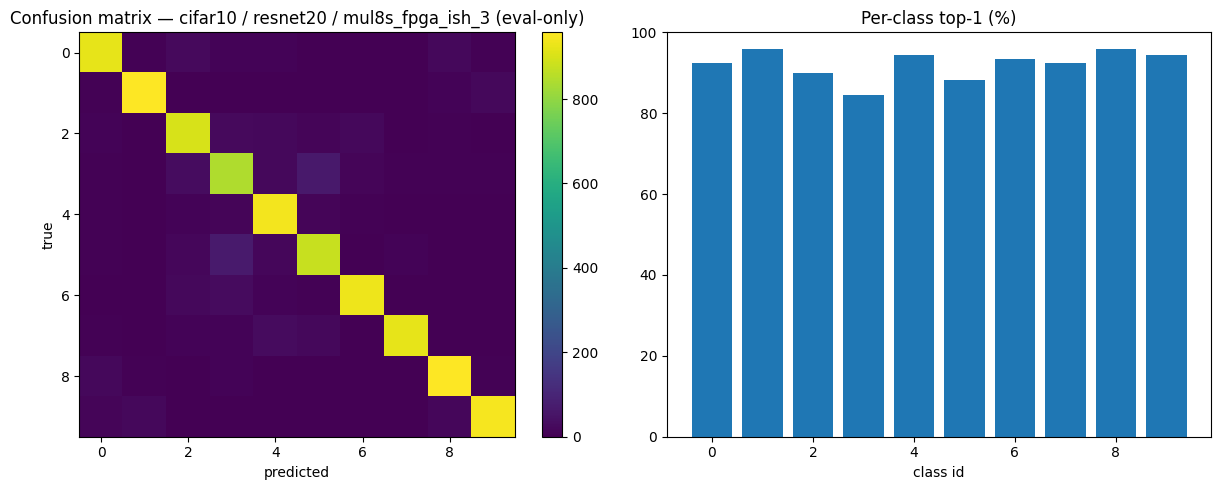

In [5]:
ds, mdl = CM_PICK
row = df[(df.dataset == ds) & (df.model == mdl)
          & (df.multiplier == MULTIPLIER) & (df.retrained_epochs == 0)]
if row.empty:
    print(f"No eval-only row found for {CM_PICK} / {MULTIPLIER} "
          f"(is it filtered out by DATASET={DATASET}?).")
else:
    short = MULTIPLIER.replace("mul8s_", "")
    new_path    = CM_DIR / ds / f"{mdl}_{short}_e0.npy"
    legacy_path = RUNS_DIR / str(row.iloc[0]["run_id"]) / "confusion_matrix.npy"
    cm_file = new_path if new_path.exists() else legacy_path
    if not cm_file.exists():
        print(f"confusion matrix not found (looked at {new_path} and {legacy_path}); "
              f"re-run the sweep notebook.")
    else:
        cm = np.load(cm_file)
        per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        im = axes[0].imshow(cm, aspect="auto")
        axes[0].set_title(f"Confusion matrix — {ds} / {mdl} / {MULTIPLIER} (eval-only)")
        axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
        fig.colorbar(im, ax=axes[0])
        axes[1].bar(np.arange(len(per_class_acc)), per_class_acc * 100)
        axes[1].set_title("Per-class top-1 (%)")
        axes[1].set_xlabel("class id")
        axes[1].set_ylim(0, 100)
        fig.tight_layout()